# 12. Validación cruzada anidada y estimación por noche

**Qué hace.** Los números de desarrollo (área bajo la curva 0,876, acierto por registro 0,81) son optimistas: F, su post-procesado y su umbral se eligieron con esos mismos sujetos. Acá se repite **toda la elección** dejando afuera, por turnos, un grupo de sujetos, y cada grupo se evalúa con un detector elegido sin verlo. Es la estimación de desarrollo que se reporta (condición 3 de `plan_test.md`). Con esas mismas predicciones se mide, por primera vez con sujetos de afuera, qué tan bien se estima la apnea de cada noche.

**Reglas (fijadas antes de correr).**
1. **Datos:** los 47 registros de desarrollo (19 sujetos). Las 1.134 candidatas de acoplamiento y las 60 de variabilidad cardíaca de E3, recalculadas con el pipeline vigente (filtro 0,5–45 Hz orden 3, marcas de la base con parábola, sin Wiener), en `results/e3_v3/`.
2. **Grupos:** los 5 grupos de sujetos de E3 (`subject_folds`, semilla 2026, separando sujetos con y sin apnea).
3. **En cada grupo, solo con los otros cuatro,** para F y para la referencia: (a) feature, con no inferioridad δ = 0,02 → acierto por registro → la más simple (E3a); (b) post-procesado, las 9 combinaciones sobre el grupo de no inferiores, con la misma regla (E3b); (c) umbral de Youden. Bootstrap de 1.000 remuestreos para el área bajo la curva y 300 para el acierto por registro (los de la validación cruzada de E3a).
4. **Minutos:** se elige sobre los minutos comunes a todas las candidatas (como E3a). Se evalúa afuera sobre los que define el plan para test: con etiqueta, 20 % o menos de intervalos corregidos y F y referencia calculables.
5. **En los sujetos de afuera:** el área bajo la curva **por grupo** (cada grupo puede elegir otra feature, y sus puntajes no se mezclan), con su media y un intervalo por bootstrap de sujetos; sensibilidad, especificidad y exactitud balanceada juntando las decisiones; acierto por registro; y la diferencia entre F y la referencia en las dos medidas. Es descriptivo: la prueba de H2 es en test.
6. **Estimación por noche** (`record_metrics`): minutos de apnea por hora estimados contra anotados (Bland–Altman), fracción de minutos marcados como apnea en las noches de control, y categorías A/B/C con la regla del plan (100 y 5 minutos).
7. **Candidata: calibración por noche.** En cada grupo, con las noches de entrenamiento se ajusta una recta entre la fracción estimada y la real, y se aplica a las de afuera (recortada entre 0 y 1). Como es creciente, no cambia el acierto por registro ni la hipótesis principal. **Se adopta si baja el error absoluto medio de los minutos de apnea por hora en las noches de afuera, con el intervalo de la diferencia completo por debajo de 0** (bootstrap por sujeto). Si se adopta, entra como desvío fechado de `plan_test.md` (resultados secundarios).
8. **Control contra filtraciones:** se repite el primer grupo con las etiquetas de sus sujetos mezcladas al azar. Lo elegido (feature, sentido, umbral y recta) tiene que dar idéntico.
9. **Qué esperar de test** (descriptivo): con las predicciones de afuera se sortean 500 veces 10 de los 19 sujetos y se aplica el procedimiento del plan (bootstrap por sujeto, p bilateral, Holm), con 1.000 remuestreos en lugar de 10.000 por tiempo.

**Lo que queda fijo y deja optimismo residual (se declara):** la banda de apnea entró a E3a después de que E2 la mostrara fuerte con los mismos sujetos; la forma "potencia sola" se agregó después de la primera corrida de E3a; la regla de no inferioridad se eligió con todos los sujetos; las etapas 4.1 a 4.4 y los minutos malos se decidieron con todos los sujetos (ninguna cambió el pipeline, salvo el filtro, elegido por una especificación sin etiquetas). La recta de calibración se ajusta con predicciones de las noches de entrenamiento, que son un poco optimistas.

In [1]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.environ["PYTHONPATH"] = str(ROOT)
from src.config import RESULTS_DIR, SPLIT_CSV
from src.evaluation.metrics import minute_metrics, night_minutes, record_metrics
from src.features.variants import coupling_variants, hrv_variants
from src.stats.compare import subject_folds
from src.stats.nested import (fold_auc, nested_cv, night_error_boot, record_agreement_boot,
                              record_table, select_pipeline, subsample_h2)

FIG = RESULTS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
CACHE = RESULTS_DIR / "e3_v3"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"
COLOR_CAT = {"A": NARANJA, "B": GRIS, "C": AZUL}
split = pd.read_csv(SPLIT_CSV).set_index("record")
DEV = list(split.index[split.set == "dev"])
subject_of = split.loc[DEV, "subject"]
KW = dict(n_boot=1000, n_boot_rec=300, seed=2026)
print(len(DEV), "registros de desarrollo,", subject_of.nunique(), "sujetos")

47 registros de desarrollo, 19 sujetos


In [2]:
f_coup, f_hrv = CACHE / "acoplamiento.parquet", CACHE / "hrv.parquet"
if not (f_coup.exists() and f_hrv.exists()):
    # Las mismas candidatas que E3a, con el pipeline vigente (tarda unos minutos en paralelo).
    from concurrent.futures import ProcessPoolExecutor
    from src.features.build import record_feature_tables
    from src.features.variants import BANDS
    W, E, R = (180, 240, 300, 360, 420, 512), ("welch3", "welch7", "multitaper"), ("area", "baseline", "combined")
    CACHE.mkdir(parents=True, exist_ok=True)
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 1)) as ex:
        res = list(ex.map(record_feature_tables, DEV, [W] * len(DEV), [E] * len(DEV), [R] * len(DEV),
                          [BANDS] * len(DEV)))
    pd.concat([r[0] for r in res], ignore_index=True).to_parquet(f_coup)
    pd.concat([r[1] for r in res], ignore_index=True).to_parquet(f_hrv)
coup, hrv = pd.read_parquet(f_coup), pd.read_parquet(f_hrv)
wide_c, meta_c = coupling_variants(coup)
wide_h, meta_h = hrv_variants(hrv)
info = coup.groupby(["record", "minute"])[["label", "corrected"]].first()
eval_idx = (wide_c.dropna().index.intersection(wide_h.dropna().index)
            .intersection(info.index[(info.label >= 0) & (info.corrected <= 0.2)]))
y_all = info.loc[eval_idx, "label"].to_numpy(int)
subj_all = subject_of.loc[eval_idx.get_level_values("record")].to_numpy()
tiene_apnea = pd.Series(y_all, index=subj_all).groupby(level=0).max().astype(bool)
folds = subject_folds(tiene_apnea, k=5)
families = {"F": (wide_c, meta_c), "HRV": (wide_h, meta_h)}
del coup, hrv
print(f"candidatas: acoplamiento {wide_c.shape[1]} | HRV {wide_h.shape[1]}")
print(f"minutos de elección: {len(eval_idx):,} ({y_all.mean():.1%} con apnea) | grupos: {[len(f) for f in folds]} sujetos")

candidatas: acoplamiento 1134 | HRV 60
minutos de elección: 22,125 (39.9% con apnea) | grupos: [4, 4, 4, 4, 3] sujetos


## Control: la elección con todos los sujetos

Antes de anidar, la misma elección con los 19 sujetos. Con la caché vieja (filtro anterior) daba F = `area|240s|welch3|apnea|potencia sola|none|k1` y HRV = `hrv|180s|vlf|none|k1`. Si con el pipeline vigente elige otra cosa, se reporta: el pipeline congelado no cambia por esto, pero es un dato sobre la estabilidad de la elección.

In [3]:
t0 = time.time()
congelado = {"F": "area|240s|welch3|apnea|potencia sola|none|k1", "HRV": "hrv|180s|vlf|none|k1"}   # E3b
todos = {fam: select_pipeline(w, m, y_all, eval_idx, subj_all, **KW) for fam, (w, m) in families.items()}
for fam, c in todos.items():
    print(f"{fam}: {c['variante']} | umbral {c['umbral']:.4g} | congelado: {congelado[fam]} | "
          f"{'coincide' if c['variante'] == congelado[fam] else 'NO coincide'}")
print(f"tiempo: {(time.time() - t0) / 60:.1f} min")

F: area|240s|welch3|apnea|potencia sola|none|k1 | umbral -6.949 | congelado: area|240s|welch3|apnea|potencia sola|none|k1 | coincide
HRV: hrv|180s|vlf|none|k1 | umbral 0.001258 | congelado: hrv|180s|vlf|none|k1 | coincide
tiempo: 1.1 min


## Validación cruzada anidada

In [4]:
f_pred, f_ch = CACHE / "anidada_pred.parquet", CACHE / "anidada_elecciones.parquet"
t0 = time.time()
if f_pred.exists() and f_ch.exists():
    pred, choices = pd.read_parquet(f_pred), pd.read_parquet(f_ch)
    print("recuperado de la caché")
else:
    pred, choices = nested_cv(families, info, subject_of, eval_idx, folds, **KW)
    pred.to_parquet(f_pred); choices.to_parquet(f_ch)
print(f"tiempo: {(time.time() - t0) / 60:.1f} min | minutos evaluados afuera: {len(pred):,} | registros: "
      f"{pred.index.get_level_values('record').nunique()}")
choices[["grupo", "familia", "sujetos_afuera", "tamaño_grupo_e3a", "variante", "umbral", "cal_a", "cal_b"]].round(4)

tiempo: 4.2 min | minutos evaluados afuera: 22,275 | registros: 47


,grupo,familia,sujetos_afuera,tamaño_grupo_e3a,variante,umbral,cal_a,cal_b
0,1,F,4,13,area|240s|welch3|apnea|potencia sola|none|k1,-6.9120,0.0459,0.7622
1,1,HRV,4,7,hrv|180s|apnea|none|k1,0.0014,0.1405,0.5778
2,2,F,4,23,area|240s|welch3|apnea|potencia sola|none|k1,-6.9612,-0.0090,0.8475
3,2,HRV,4,6,hrv|240s|lf_hf|none|k1,3.0046,-0.1073,0.9840
4,3,F,4,21,area|240s|welch3|apnea|potencia sola|none|k1,-6.9225,-0.0608,0.9356
5,3,HRV,4,6,hrv|180s|apnea|none|k1,0.0016,-0.0436,0.8542
6,4,F,4,19,area|240s|welch3|apnea|potencia sola|none|k1,-6.9061,-0.0543,0.9351
7,4,HRV,4,10,hrv|180s|apnea|none|k1,0.0015,-0.0834,0.9860
8,5,F,3,13,area|240s|welch3|apnea|potencia sola|none|k1,-6.9555,-0.0112,0.8365
9,5,HRV,3,5,hrv|180s|apnea|none|k1,0.0014,0.1215,0.4982


In [5]:
# Control contra filtraciones: el grupo 1 con las etiquetas de sus sujetos mezcladas.
out1 = subject_of.index[subject_of.isin(folds[0])]
perm = info.copy()
m = perm.index.get_level_values("record").isin(out1)
perm.loc[m, "label"] = np.random.default_rng(7).permutation(perm.loc[m, "label"].to_numpy())
pred_p, ch_p = nested_cv(families, perm, subject_of, eval_idx, folds[:1], **KW)
g1 = choices[choices.grupo == 1].reset_index(drop=True)
num = ["signo", "umbral", "cal_a", "cal_b"]
igual = (ch_p["variante"].tolist() == g1["variante"].tolist()
         and np.allclose(ch_p[num].to_numpy(float), g1[num].to_numpy(float), rtol=1e-12, atol=0))
p1 = pred[pred.grupo == 1]
igual_puntajes = np.allclose(pred_p.loc[p1.index, ["score_F", "score_HRV"]], p1[["score_F", "score_HRV"]])
print(f"lo elegido es idéntico: {igual} | los puntajes de afuera son idénticos: {igual_puntajes}")
assert igual and igual_puntajes

lo elegido es idéntico: True | los puntajes de afuera son idénticos: True


## Resultados en los sujetos de afuera

In [6]:
auc = fold_auc(pred, subject_of, n_boot=2000)
print("Área bajo la curva por minuto (por grupo, promediada):")
display(auc)
mm = pd.DataFrame({fam: {k: v for k, v in minute_metrics(pred.label, pred[f"pred_{fam}"]).items() if k != "matriz"}
                   for fam in ("F", "HRV")}).T
print("Decisiones juntando los cinco grupos:")
display(mm[["Se", "Esp", "exactitud", "exactitud_balanceada"]].astype(float).round(4))
tabla = record_table(pred, subject_of)
acu = record_agreement_boot(tabla, n_boot=2000)
print("Acierto por registro (Spearman entre la fracción estimada y la real):")
display(acu.astype(float).round(3))

Área bajo la curva por minuto (por grupo, promediada):


,media,ic_lo,ic_hi,por_grupo
F,0.851119,0.760386,0.915544,"[0.947, 0.872, 0.783, 0.689, 0.964]"
HRV,0.729232,0.635058,0.836555,"[0.958, 0.528, 0.745, 0.531, 0.884]"
F - HRV,0.121886,0.021508,0.193081,"[-0.011, 0.344, 0.038, 0.159, 0.08]"


Decisiones juntando los cinco grupos:


,Se,Esp,exactitud,exactitud_balanceada
F,0.8387,0.7484,0.7843,0.7935
HRV,0.6902,0.6020,0.6371,0.6461


Acierto por registro (Spearman entre la fracción estimada y la real):


,spearman,ic_lo,ic_hi
est_F,0.807,0.547,0.936
est_HRV,0.234,-0.225,0.644
est_F - est_HRV,0.573,0.217,0.929


## Estimación por noche

F: minutos de apnea por hora, sesgo +5.0 (límites -21.1 a +31.0) | categoría correcta en 57% de las noches
HRV: minutos de apnea por hora, sesgo +7.3 (límites -35.6 a +50.1) | categoría correcta en 51% de las noches

Categorías con F (filas: real; columnas: estimada):


estimada,A,B,C
real,,,
A,25,2,0
B,6,2,0
C,0,12,0


Noches de control (12): fracción de minutos marcados como apnea con F, mediana 10.6% (de 5.2% a 15.9%); real 0.3%


,minutos,real,estimada F,minutos de apnea estimados,categoría estimada
record,,,,,
c01,470,0.000,0.140,66.0,B
c02,489,0.002,0.104,51.0,B
c03,415,0.000,0.159,66.0,B
c06,458,0.002,0.070,32.0,B
c07,421,0.010,0.052,22.0,B
c09,453,0.004,0.097,44.0,B
c10,418,0.002,0.108,45.0,B
x04,444,0.000,0.155,69.0,B
x17,289,0.003,0.138,40.0,B


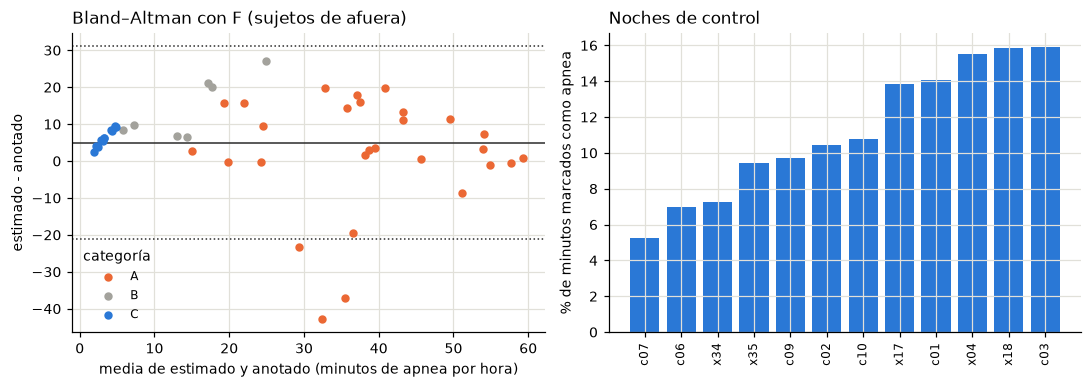

In [7]:
cat_real = split.loc[tabla.index, "category"]
noches = {}
for fam in ("F", "HRV"):
    nm = night_minutes(pred.index.get_level_values("record"), pred.label, pred[f"pred_{fam}"])
    noches[fam] = record_metrics(nm.min_estimados, nm.min_anotados, nm.horas, records=nm.index)
for fam, r in noches.items():
    print(f"{fam}: minutos de apnea por hora, sesgo {r['sesgo']:+.1f} (límites {r['lim_inf']:+.1f} a {r['lim_sup']:+.1f}) | "
          f"categoría correcta en {r['acierto_categoria']:.0%} de las noches")
print("\nCategorías con F (filas: real; columnas: estimada):")
display(noches["F"]["matriz_categorias"])
ctrl = tabla[cat_real == "C"]
print(f"Noches de control ({len(ctrl)}): fracción de minutos marcados como apnea con F, mediana "
      f"{ctrl.est_F.median():.1%} (de {ctrl.est_F.min():.1%} a {ctrl.est_F.max():.1%}); "
      f"real {ctrl.real.mean():.1%}")
display(pd.DataFrame({"minutos": ctrl.minutos, "real": ctrl.real, "estimada F": ctrl.est_F,
                      "minutos de apnea estimados": (ctrl.est_F * ctrl.minutos).round(0),
                      "categoría estimada": noches["F"]["tabla"].loc[ctrl.index, "categoria_estimada"]}).round(3))

t = noches["F"]["tabla"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
for c in "ABC":
    s = cat_real[t.index] == c
    a1.scatter(t.media[s], t.diferencia[s], s=20, color=COLOR_CAT[c], label=c, zorder=3)
r = noches["F"]
for v, ls in ((r["sesgo"], "-"), (r["lim_inf"], ":"), (r["lim_sup"], ":")):
    a1.axhline(v, color=TINTA, lw=1, ls=ls)
a1.set_xlabel("media de estimado y anotado (minutos de apnea por hora)")
a1.set_ylabel("estimado - anotado"); a1.legend(frameon=False, fontsize=8, title="categoría")
a1.set_title("Bland–Altman con F (sujetos de afuera)", loc="left")
o = ctrl.sort_values("est_F")
a2.bar(range(len(o)), 100 * o.est_F, color=AZUL)
a2.set_xticks(range(len(o)), o.index, rotation=90, fontsize=8)
a2.set_ylabel("% de minutos marcados como apnea"); a2.set_title("Noches de control", loc="left")
fig.tight_layout(); fig.savefig(FIG / "12_por_noche.png")

## Candidata: calibración por noche

In [8]:
cal = {}
for fam in ("F", "HRV"):
    cal[fam] = night_error_boot(tabla, f"est_{fam}", f"cal_{fam}", n_boot=2000)
    nm = night_minutes(pred.index.get_level_values("record"), pred.label, pred[f"pred_{fam}"])
    est_cal = (tabla.loc[nm.index, f"cal_{fam}"] * nm.minutos_evaluados).to_numpy()
    rc = record_metrics(est_cal, nm.min_anotados, nm.horas, records=nm.index)
    cal[fam].update({"sesgo calibrado": rc["sesgo"], "categoría correcta calibrada": rc["acierto_categoria"],
                     "categoría correcta sin calibrar": noches[fam]["acierto_categoria"]})
    if fam == "F":
        matriz_cal = rc["matriz_categorias"]
display(pd.DataFrame(cal).T.astype(float).round(3))
ADOPTA_CAL = bool(cal["F"]["ic_hi"] < 0)
print(f"-> regla (F): {'se adopta la calibración por noche' if ADOPTA_CAL else 'no se adopta la calibración por noche'}")
print("\nCategorías con F calibrada (filas: real; columnas: estimada):")
display(matriz_cal)

,error_est_F,error_cal_F,diferencia,ic_lo,ic_hi,sesgo calibrado,categoría correcta calibrada,categoría correcta sin calibrar,error_est_HRV,error_cal_HRV
F,10.627,9.803,-0.824,-2.666,1.238,0.091,0.574,0.574,NaN,NaN
HRV,NaN,NaN,0.528,-1.982,3.375,0.662,0.426,0.511,17.92,18.447


-> regla (F): no se adopta la calibración por noche

Categorías con F calibrada (filas: real; columnas: estimada):


estimada,A,B,C
real,,,
A,24,3,0
B,5,3,0
C,0,12,0


## Qué esperar de test

In [9]:
misma_f = choices[choices.familia == "F"].variante.nunique() == 1
misma_h = choices[choices.familia == "HRV"].variante.nunique() == 1
con_auc = bool(misma_f and misma_h)
print(f"todos los grupos eligieron la misma F: {misma_f} | la misma referencia: {misma_h} -> "
      f"{'se incluye' if con_auc else 'no se incluye'} el área bajo la curva (M1)")
t0 = time.time()
pot = subsample_h2(pred, subject_of, n_subjects=10, n_draws=500, n_boot=1000, with_auc=con_auc)
if con_auc:
    res = {"M1 (área bajo la curva)": pot["confirma_M1"].mean(),
           "M2 (acierto por registro)": pot["confirma_M2"].mean(),
           "alguna de las dos": (pot["confirma_M1"] | pot["confirma_M2"]).mean()}
else:
    # Sin M1 no se puede aplicar Holm sobre las dos medidas. Con Holm, M2 se confirma con
    # p < 0,05 si M1 sale con p < 0,025, y necesita p < 0,025 en el peor caso.
    pos = pot["dif_M2"] > 0
    res = {"M2 con p < 0,05 (si M1 también sale significativa)": (pos & (pot["p_M2"] < 0.05)).mean(),
           "M2 con p < 0,025 (peor caso de Holm)": (pos & (pot["p_M2"] < 0.025)).mean()}
print(f"tiempo: {(time.time() - t0) / 60:.1f} min")
print("Fracción de sorteos de 10 sujetos en que H2 se confirmaría:")
for k, v in res.items():
    print(f"  {k}: {v:.0%}")
display(pot[[c for c in pot.columns if c.startswith("dif_")]].describe().round(3))

todos los grupos eligieron la misma F: True | la misma referencia: False -> no se incluye el área bajo la curva (M1)


tiempo: 6.6 min
Fracción de sorteos de 10 sujetos en que H2 se confirmaría:
  M2 con p < 0,05 (si M1 también sale significativa): 79%
  M2 con p < 0,025 (peor caso de Holm): 62%


,dif_M2
count,500.000
mean,0.567
std,0.191
min,0.111
25%,0.439
50%,0.559
75%,0.689
max,1.183


## Decisión

**Estimación honesta de desarrollo (la que se reporta).** Con todo elegido sin ver a los sujetos de afuera, F da:
- área bajo la curva por minuto **0,851** (intervalo de confianza 0,760 a 0,916; por grupo, de 0,689 a 0,964);
- sensibilidad **0,839**, especificidad **0,748** y exactitud balanceada **0,794**;
- acierto por registro **0,807** (0,547 a 0,936).

El optimismo de F es chico: 0,875 con todos los sujetos contra 0,851 afuera (0,024), parecido al de E3a (0,021).

**La elección de F es estable.** Los cinco grupos eligieron la misma F (potencia cruzada en la banda de apnea, 240 s, sin post-procesado), con umbrales entre −6,96 y −6,91. Con todos los sujetos y el pipeline vigente sale exactamente la F congelada, con el mismo umbral (−6,949).

**La referencia no es estable y era optimista.** Cuatro grupos eligieron la potencia del ritmo cardíaco en la banda de apnea con 180 s, y uno el cociente entre baja y alta frecuencia con 240 s. Afuera da 0,729, contra 0,81 con todos los sujetos. En test se usa la referencia congelada (muy baja frecuencia, 180 s).

**F contra la referencia en sujetos de afuera** (descriptivo; la prueba de H2 es en test): +0,122 en área bajo la curva (0,022 a 0,193) y +0,573 en acierto por registro (0,217 a 0,929). Los dos intervalos quedan por encima de 0.

**Estimación por noche.** Sesgo de +5,0 minutos de apnea por hora (límites de −21 a +31). La categoría es correcta en el 57 % de las noches. **Las 12 noches de control quedan como B:** F marca como apnea entre el 5 % y el 16 % de sus minutos (de 22 a 70 minutos), y el corte de B es de 5 minutos. Con una especificidad de alrededor de 0,89 en esas noches, ese corte es inalcanzable para un detector minuto a minuto.

**Calibración por noche: no se adopta.** Baja el error de 10,6 a 9,8 minutos por hora, pero el intervalo de la diferencia (−2,7 a +1,2) incluye el 0. Tampoco arregla las noches de control.

**Control contra filtraciones:** con las etiquetas del grupo 1 mezcladas, lo elegido y los puntajes de afuera dan idénticos.

**Qué esperar de test.** Para el área bajo la curva no se puede estimar así, porque los grupos eligieron referencias distintas y sus puntajes no se pueden juntar. Para el acierto por registro, en sorteos de 10 sujetos H2 se confirmaría en el 62 % (peor caso de Holm) al 79 % (si la otra medida también sale significativa). Aunque F sea mejor, hay entre un 20 % y un 40 % de chances de que test no lo muestre con 10 sujetos.

**Pendiente antes de congelar:** el resultado secundario de categorías A/B/C va a clasificar casi seguro las noches de control como B. Es una decisión de criterio: reportarlo como limitación, o fijar antes de abrir test, como desvío del plan, una regla de categoría calibrada en desarrollo. No afecta a la hipótesis principal.